# Stage 1: refund intent

In [1]:
import numpy as np
import pandas as pd
import re
import os

from sklearn.dummy import DummyClassifier

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, fbeta_score, accuracy_score, make_scorer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import joblib
from claimlens.data import load_raw_data, FirstMessage, CleanText, FullChat
from claimlens.embeddings import embed_texts


/Users/finn/code/MUlbing/ClaimLens/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1019 16:12:29.440000 42366 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8916.90it/s]


In [2]:
raw_data = load_raw_data("../raw_data/abcd_v1.1.json")

df = FirstMessage().build_df(raw_data)

full_df = FullChat().build_df(raw_data)
df = df.merge(full_df[["split", "id", "full_msgs", "refund_output"]], on=["split", "id"], how="left")

df.columns.tolist()

['split',
 'id',
 'flow',
 'subflow',
 'first_msgs',
 'refund_intent',
 'full_msgs',
 'refund_output']

In [3]:
cleaner = CleanText()

df['clean_text'] = df['first_msgs'].apply(cleaner.clean)

light_cleaner = CleanText(remove_stop_words=False, lemmatize=False)
df["light_clean_text"] = df["first_msgs"].apply(light_cleaner.clean)

print("empty after cleaning:", (df["clean_text"] == "").sum())
print("empty after light cleaning:", (df["light_clean_text"] == "").sum())


empty after cleaning: 0
empty after light cleaning: 0


In [4]:
display(df[["first_msgs", "clean_text", "light_clean_text"]].head(10))

,first_msgs,clean_text,light_clean_text
0,"I need to return an item, can you help me with...",need return item help,i need to return an item can you help me with ...
1,just wanted to check on the status of a refund,want check status refund,just wanted to check on the status of a refund
2,I have got a promo code and I want to know whe...,get promo code want know expire like use buy h...,i have got a promo code and i want to know whe...
3,I would like to change my shipping deatails as...,like change ship deatails change recently move,i would like to change my shipping deatails as...
4,I have a really cool party coming up. And I ne...,cool party come need new clothe soon possible ...,i have a really cool party coming up and i nee...
5,I want an extension for my shopping service. I...,want extension shop service need time get money,i want an extension for my shopping service i ...
6,I am trying to check the status of my order bu...,try check status order forget username cannot ...,i am trying to check the status of my order bu...
7,I am trying to buy a pair of boots but they ar...,try buy pair boot not get add cart,i am trying to buy a pair of boots but they ar...
8,I accidently ordered the wrong item and was wo...,accidently order wrong item wonder change item,i accidently ordered the wrong item and was wo...
9,I would like to confirm my address is correct ...,like confirm address correct order able,i would like to confirm my address is correct ...


In [5]:
TARGET = "refund_intent"

train = df[df["split"] == "train"]
val = df[df["split"] == "dev"]
test = df[df["split"] == "test"]

X_train = train["clean_text"]
y_train = train[TARGET]

X_val = val["clean_text"]
y_val = val[TARGET]

X_test = test["clean_text"]
y_test = test[TARGET]

train_dev = df[df["split"].isin(["train", "dev"])]
X_td = train_dev["clean_text"]
y_td = train_dev[TARGET]


X_td_raw = train_dev["first_msgs"]
X_td_light = train_dev["light_clean_text"]


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

f2_scorer = make_scorer(fbeta_score, beta=2)

## Baseline

In [6]:
print(y_train.value_counts(normalize=True))

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred = dummy.predict(X_val)

print("accuracy:", accuracy_score(y_val, y_pred))
print("precision:", precision_score(y_val, y_pred, zero_division=0))
print("recall:", recall_score(y_val, y_pred))

refund_intent
0    0.815783
1    0.184217
Name: proportion, dtype: float64
accuracy: 0.8137450199203188
precision: 0.0
recall: 0.0


In [7]:
def plot_confusion(y_true, y_pred, title):
    """Confusion matrix with plain-language labels, counts and row percentages."""
    # Counts and row percentages (each row adds up to 100%)
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = confusion_matrix(y_true, y_pred, normalize="true")

    # Unpack the four cells: correct no, false alarm, missed, correct yes
    tn, fp, fn, tp = cm.ravel()
    tn_pct, fp_pct, fn_pct, tp_pct = cm_pct.ravel()

    # Text inside each cell, in the same layout as the grid
    labels = [
        [f"Correct: no refund intent\n{tn} ({tn_pct:.0%})", f"False alarm\n{fp} ({fp_pct:.0%})"],
        [f"Missed refund intent\n{fn} ({fn_pct:.0%})", f"Correct: refund intent\n{tp} ({tp_pct:.0%})"],
    ]

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm_pct,
        annot=labels,
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=1,
        cbar=False,
        xticklabels=["Predicted: no refund", "Predicted: refund"],
        yticklabels=["Actually: no refund", "Actually: refund"],
    )
    plt.title(title)
    plt.show()

## TF-IDF models (comparison)

In [8]:
models = {
    "count + none": make_pipeline(
        CountVectorizer(),
        LogisticRegression(max_iter=1000),
    ),
    "tfidf + balanced": make_pipeline(
        TfidfVectorizer(),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "tfidf + balanced + ngrams": make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
}

In [9]:
cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_td, y_td, cv=cv,
        scoring={"precision": "precision",
                 "recall": "recall",
                 "f2": f2_scorer}
    )
    cv_results.append({
        "model": name,
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f2": scores["test_f2"].mean(),
        "f2_std": scores["test_f2"].std(),
    })
cv_results_df = pd.DataFrame(cv_results).sort_values("f2", ascending=False)
cv_best_name = cv_results_df.iloc[0]["model"]
print("Best model (CV):", cv_best_name)


cv_results_df

Best model (CV): tfidf + balanced + ngrams


,model,precision,recall,f2,f2_std
2,tfidf + balanced + ngrams,0.800238,0.917218,0.891112,0.010710
1,tfidf + balanced,0.742514,0.911219,0.871576,0.009829
0,count + none,0.903996,0.807434,0.825019,0.013295


In [10]:
cleaner_full = CleanText(remove_stop_words=True, lemmatize=True)
cleaner_lemmas = CleanText(remove_stop_words=False, lemmatize=True)
cleaner_light = CleanText(remove_stop_words=False, lemmatize=False)

cleaning_models = {
    "stop words removed + lemmas": make_pipeline(
        TfidfVectorizer(preprocessor=cleaner_full.clean, ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "stop words kept + lemmas": make_pipeline(
        TfidfVectorizer(preprocessor=cleaner_lemmas.clean, ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "stop words kept, no lemmas": make_pipeline(
        TfidfVectorizer(preprocessor=cleaner_light.clean, ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
}

cleaning_results = []

for name, model in cleaning_models.items():
    # Raw text in: each pipeline cleans it its own way
    scores = cross_validate(
        model, X_td_raw, y_td, cv=cv,
        scoring={"precision": "precision",
                 "recall": "recall",
                 "f2": f2_scorer}
    )
    cleaning_results.append({
        "cleaning": name,
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f2": scores["test_f2"].mean(),
        "f2_std": scores["test_f2"].std(),
    })

cleaning_results_df = pd.DataFrame(cleaning_results).sort_values("f2", ascending=False)
cleaning_results_df

,cleaning,precision,recall,f2,f2_std
2,"stop words kept, no lemmas",0.839237,0.916024,0.899523,0.014602
1,stop words kept + lemmas,0.827317,0.918419,0.898601,0.010668
0,stop words removed + lemmas,0.800238,0.917218,0.891112,0.010710


In [11]:
best_pipe = models[cv_best_name]


print(best_pipe.named_steps.keys())

param_grid = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidfvectorizer__min_df": [1, 2],
    "tfidfvectorizer__sublinear_tf": [True, False],
    "logisticregression__C": [0.1, 1.0, 10.0, 100],
    "logisticregression__class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(
    estimator=best_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring=f2_scorer,
    n_jobs=-1,
    verbose=1,
    refit=True
)
grid_search.fit(X_td, y_td)

print(f"Best CV F2: {grid_search.best_score_:.4f}")

tfidf_model = grid_search.best_estimator_

dict_keys(['tfidfvectorizer', 'logisticregression'])
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best CV F2: 0.9060


In [12]:
tfidf_probs = cross_val_predict(
    tfidf_model, X_td, y_td, cv=cv, method="predict_proba"
)[:, 1]

tfidf_threshold_results = []

for threshold in [0.35, 0.40, 0.42, 0.44, 0.46, 0.48, 0.50, 0.55]:
    y_pred = (tfidf_probs >= threshold).astype(int)

    tfidf_threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_td, y_pred),
        "recall": recall_score(y_td, y_pred),
        "f2": fbeta_score(y_td, y_pred, beta=2),
    })

pd.DataFrame(tfidf_threshold_results)

,threshold,precision,recall,f2
0,0.35,0.775309,0.941812,0.903025
1,0.40,0.797649,0.936413,0.904928
2,0.42,0.803618,0.932813,0.903755
3,0.44,0.812565,0.931014,0.904640
4,0.46,0.822187,0.929214,0.905636
5,0.48,0.831539,0.926815,0.906052
6,0.50,0.837134,0.925015,0.905993
7,0.55,0.857785,0.915417,0.903279


In [13]:
TFIDF_THRESHOLD = 0.44

precision: 0.8140703517587939
recall: 0.9204545454545454
f2: 0.8970099667774086


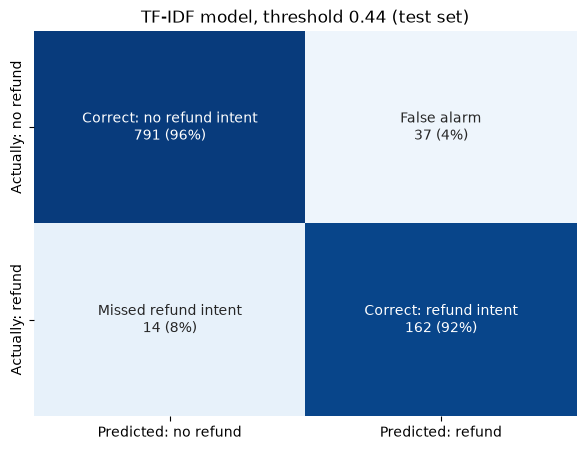

In [14]:
tfidf_test_probs = tfidf_model.predict_proba(X_test)[:, 1]
tfidf_test_pred = (tfidf_test_probs >= TFIDF_THRESHOLD).astype(int)

print("precision:", precision_score(y_test, tfidf_test_pred))
print("recall:", recall_score(y_test, tfidf_test_pred))
print("f2:", fbeta_score(y_test, tfidf_test_pred, beta=2))

plot_confusion(y_test, tfidf_test_pred, f"TF-IDF model, threshold {TFIDF_THRESHOLD} (test set)")

## Sentence model (final)

In [15]:
train_dev_embeddings = embed_texts(X_td_light)

test_embeddings = embed_texts(test["light_clean_text"])

In [16]:

os.makedirs("../data/processed", exist_ok=True)

# Save the meaning vectors, so notebook 2 doesn't have to compute them again
np.save("../data/processed/train_dev_embeddings.npy", train_dev_embeddings)
np.save("../data/processed/test_embeddings.npy", test_embeddings)

In [17]:
sentence_scores = cross_validate(
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    train_dev_embeddings, y_td, cv=cv,
    scoring={"precision": "precision",
             "recall": "recall",
             "f2": f2_scorer}
)

print("precision:", sentence_scores["test_precision"].mean())
print("recall:", sentence_scores["test_recall"].mean())
print("f2:", sentence_scores["test_f2"].mean())

precision: 0.7614104559930331
recall: 0.9298034561507615
f2: 0.8903898671202277


In [18]:
train_dev_embeddings_full = embed_texts(X_td)

sentence_cleaning_results = []

for name, embeddings in [("full cleaning", train_dev_embeddings_full),
                         ("light cleaning", train_dev_embeddings)]:
    # Same classifier, same slices: only the cleaning differs
    scores = cross_validate(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        embeddings, y_td, cv=cv,
        scoring={"precision": "precision",
                 "recall": "recall",
                 "f2": f2_scorer}
    )
    sentence_cleaning_results.append({
        "cleaning": name,
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f2": scores["test_f2"].mean(),
        "f2_std": scores["test_f2"].std(),
    })

pd.DataFrame(sentence_cleaning_results).sort_values("f2", ascending=False)

,cleaning,precision,recall,f2,f2_std
1,light cleaning,0.76141,0.929803,0.890390,0.012558
0,full cleaning,0.68944,0.906414,0.852561,0.006648


In [19]:
sentence_probs_td = cross_val_predict(
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    train_dev_embeddings, y_td, cv=cv, method="predict_proba",
)[:, 1]

sentence_threshold_results = []

for threshold in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    # 1 if the probability reaches the threshold, else 0
    y_pred = (sentence_probs_td >= threshold).astype(int)

    sentence_threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_td, y_pred),
        "recall": recall_score(y_td, y_pred),
        "f2": fbeta_score(y_td, y_pred, beta=2),
    })

pd.DataFrame(sentence_threshold_results)

,threshold,precision,recall,f2
0,0.35,0.658416,0.957409,0.877695
1,0.40,0.694640,0.948410,0.883833
2,0.45,0.732460,0.939412,0.889166
3,0.50,0.761297,0.929814,0.890395
4,0.55,0.786154,0.919616,0.889417
5,0.60,0.815987,0.912418,0.891350
6,0.65,0.839910,0.893821,0.882492
7,0.70,0.868578,0.872226,0.871494


In [20]:
SENTENCE_THRESHOLD = 0.60

In [21]:
sentence_classifier = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
sentence_classifier.fit(train_dev_embeddings, y_td)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

precision: 0.785
recall: 0.8920454545454546
f2: 0.8683628318584071


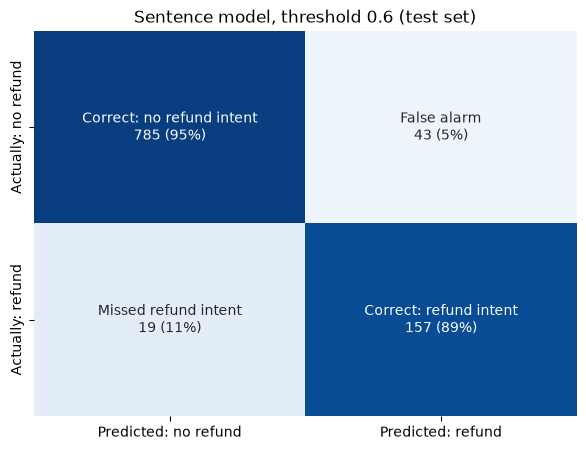

In [22]:
# Refund probabilities for the test claims, turned into yes/no with the chosen threshold
sentence_test_probs = sentence_classifier.predict_proba(test_embeddings)[:, 1]
sentence_test_pred = (sentence_test_probs >= SENTENCE_THRESHOLD).astype(int)

print("precision:", precision_score(y_test, sentence_test_pred))
print("recall:", recall_score(y_test, sentence_test_pred))
print("f2:", fbeta_score(y_test, sentence_test_pred, beta=2))

plot_confusion(y_test, sentence_test_pred, f"Sentence model, threshold {SENTENCE_THRESHOLD} (test set)")

## Prompt comparison

In [23]:
prompts = [
    "I have a complaint, my package arrived wet and the leather jacket is destroyed.",
    "My cat is hungry, I need to buy some food for her.",
    "The jacket I bought has a giant hole in it.",
    "The sky is blue and somehow it rained on my jacket",
    "My dog ate my shoes",
    "My package never arrived.",
    "I would like a refund, I never received my socks.",
    "I am very unhappy with my order.",
    "I have some questions about my order.",
    "My item is not as described, I'd like to return it.",
]

prompt_results = []

for prompt in prompts:
    # TF-IDF: full cleaning
    tfidf_prob = tfidf_model.predict_proba([cleaner.clean(prompt)])[0][1]

    # Sentence model: light cleaning, then a meaning vector, then the classifier
    sentence_prob = sentence_classifier.predict_proba(embed_texts([light_cleaner.clean(prompt)]))[0][1]

    # Yes/No decision, using each model's own threshold
    tfidf_flag = "Yes" if tfidf_prob >= TFIDF_THRESHOLD else "No"
    sentence_flag = "Yes" if sentence_prob >= SENTENCE_THRESHOLD else "No"

    prompt_results.append({
        "Customer message": prompt,
        "TF-IDF: refund chance": f"{tfidf_prob:.0%}",
        "TF-IDF: refund request?": tfidf_flag,
        "Sentence model: refund chance": f"{sentence_prob:.0%}",
        "Sentence model: refund request?": sentence_flag,
        "Models agree?": "Yes" if tfidf_flag == sentence_flag else "No",
    })

prompt_df = pd.DataFrame(prompt_results)
prompt_df

,Customer message,TF-IDF: refund chance,TF-IDF: refund request?,Sentence model: refund chance,Sentence model: refund request?,Models agree?
0,"I have a complaint, my package arrived wet and...",5%,No,70%,Yes,No
1,"My cat is hungry, I need to buy some food for ...",14%,No,5%,No,Yes
2,The jacket I bought has a giant hole in it.,18%,No,35%,No,Yes
3,The sky is blue and somehow it rained on my ja...,26%,No,20%,No,Yes
4,My dog ate my shoes,9%,No,70%,Yes,No
5,My package never arrived.,2%,No,10%,No,Yes
6,"I would like a refund, I never received my socks.",83%,Yes,80%,Yes,Yes
7,I am very unhappy with my order.,75%,Yes,94%,Yes,Yes
8,I have some questions about my order.,87%,Yes,39%,No,No
9,"My item is not as described, I'd like to retur...",98%,Yes,85%,Yes,Yes


In [24]:
# # Hand-written, hand-labelled messages (labels written BEFORE testing)
# realistic_df = pd.DataFrame({
#     "text": [
#         "I would like a refund, I never received my socks.",
#         "I have some questions about my order.",
#     ],
#     "refund_intent": [1, 0],
# })

# # TF-IDF: full cleaning, its own threshold
# tfidf_probs = tfidf_model.predict_proba(realistic_df["text"].apply(cleaner.clean))[:, 1]
# tfidf_pred = (tfidf_probs >= TFIDF_THRESHOLD).astype(int)

# # Sentence model: light cleaning, meaning vectors, its own threshold
# realistic_embeddings = embed_texts(realistic_df["text"].apply(light_cleaner.clean))
# sentence_probs = sentence_classifier.predict_proba(realistic_embeddings)[:, 1]
# sentence_pred = (sentence_probs >= SENTENCE_THRESHOLD).astype(int)

# # One row of scores per model
# realistic_results = []

# for name, pred in [("TF-IDF", tfidf_pred), ("Sentence model", sentence_pred)]:
#     realistic_results.append({
#         "model": name,
#         "precision": precision_score(realistic_df["refund_intent"], pred),
#         "recall": recall_score(realistic_df["refund_intent"], pred),
#         "f2": fbeta_score(realistic_df["refund_intent"], pred, beta=2),
#     })

# pd.DataFrame(realistic_results)

## Export

In [25]:

# Only the trained classifier: the sentence-transformer is loaded by name in src/claimlens/embeddings.py
joblib.dump(sentence_classifier, "../models/sentence_classifier.joblib")
joblib.dump(SENTENCE_THRESHOLD, "../models/sentence_threshold.joblib")

['../models/sentence_threshold.joblib']

In [26]:
# prompt = 'I want my money back'
# cleaned_prompt = cleaner.clean(prompt)
# print(cleaned_prompt)
# refund_prob = final_model.predict_proba([cleaned_prompt])[0][1]
# print(f"Refund request: {refund_prob:.0%}")

In [27]:
# pre_trained_model.fit(X_train, y_train)

In [28]:
from claimlens.data import REFUND_FEE

matches = []

for split in ("train", "dev", "test"):
    for chat in data[split]:
        for speaker, text in chat["original"]:
            # Keep every action that the fee rule matches, with its subflow
            if speaker == "action" and REFUND_FEE.search(text):
                matches.append({"subflow": chat["scenario"]["subflow"], "action": text})

matches_df = pd.DataFrame(matches)

# How often the rule fires per subflow
matches_df["subflow"].value_counts()

NameError: name 'data' is not defined